In [3]:
! python -m pip install gurobipy
! python -m pip install networkx
! python -m pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.3/14.3 MB 86.9 MB/s eta 0:00:00


In [4]:
import gurobipy as gp
from gurobipy import GRB
import networkx as nx
import matplotlib.pyplot as plt

# Grafo
G = nx.DiGraph()
G.add_nodes_from(["A", "B", "C", "D", "E", "F"])

edges = [
    ("A","B", 7),  ("A","C", 8),
    ("B","C",-1),  ("B","D", 4), ("B","E", 1), ("B","F", 5),
    ("C","F", 3),
    ("D","F", 1),
    ("E","C",-2), ("E","D", 0),
    ("F","E", 3),
]
G.add_weighted_edges_from(edges, weight="cost")

# b
b = {n: 0 for n in G.nodes}
b.update({"A": -1, "F": 1})

# max hop
maxHop = 2

# Modello
m = gp.Model("spH")

# Variabili
x = m.addVars(G.edges, vtype=GRB.BINARY, name="x")


# Vincoli bilanciamento
for v in G.nodes:
    inflow  = gp.quicksum(x[i, v] for i in G.predecessors(v))
    outflow = gp.quicksum(x[v, j] for j in G.successors(v))
    m.addConstr(inflow - outflow == b[v], name=f"balance[{v}]")

# Vincoli max hop
m.addConstr(gp.quicksum(x[a] for a in G.edges) <= maxHop, name="hop_limit")

# O.f.
m.setObjective(gp.quicksum(G[i][j]["cost"] * x[i, j] for (i, j) in G.edges), GRB.MINIMIZE)

# Ottimizza
m.optimize()

# Risultati
archi_in_soluzione = []
if m.status == GRB.OPTIMAL:
    print(f"O.f. = {m.objVal:.6g}")
    print(f"Limite hop = {maxHop}")
    print("\Archi in soluzione (x[i,j] = 1):")
    for (i, j) in G.edges:
        if x[i, j].X > 0.5:
            archi_in_soluzione.append((i, j))
            print(f"  {i} -> {j}")


<>:54: SyntaxWarning: invalid escape sequence '\A'
<>:54: SyntaxWarning: invalid escape sequence '\A'
/tmp/ipython-input-2503264463.py:54: SyntaxWarning: invalid escape sequence '\A'
  print("\Archi in soluzione (x[i,j] = 1):")


Restricted license - for non-production use only - expires 2026-11-23
Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (linux64 - "Ubuntu 22.04.4 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 7 rows, 11 columns and 33 nonzeros
Model fingerprint: 0xa6822ca6
Variable types: 0 continuous, 11 integer (11 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [1e+00, 8e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+00]
Found heuristic solution: objective 12.0000000
Presolve removed 7 rows and 11 columns
Presolve time: 0.00s
Presolve: All rows and columns removed

Explored 0 nodes (0 simplex iterations) in 0.01 seconds (0.00 work units)
Thread count was 1 (of 2 available processors)

Solution count 2: 11 12 

Optimal solution found (tolerance 1.00e-04)
Best objective 1.100000000000e+01, best bound 1.10000000

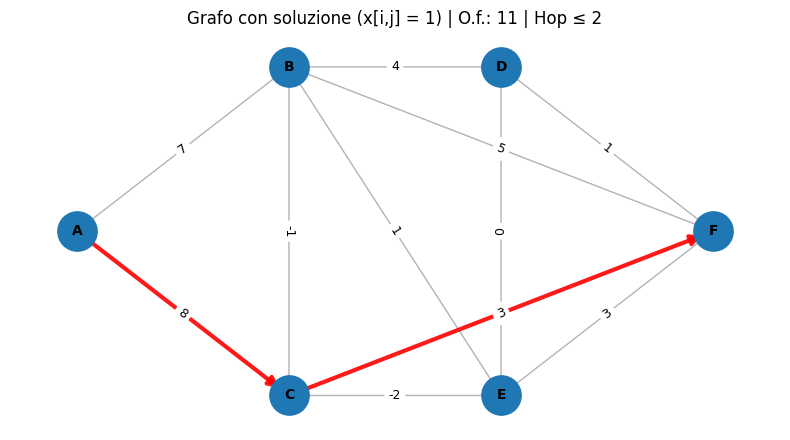

In [8]:
# Visualizzazione
pos = {
    "A": (0, 2),
    "B": (1.5, 3),
    "C": (1.5, 1),
    "D": (3, 3),
    "E": (3, 1),
    "F": (4.5, 2),
}

plt.figure(figsize=(8, 4.5))

archi_non_in_soluzione = [e for e in G.edges if e not in archi_in_soluzione]
nx.draw_networkx_edges(G, pos, edgelist=archi_non_in_soluzione, width=1.0, alpha=0.3, arrows=True)

if archi_in_soluzione:
    nx.draw_networkx_edges(G, pos, edgelist=archi_in_soluzione, width=3.0, alpha=0.9, arrows=True, arrowsize=15, edge_color="red")

nx.draw_networkx_nodes(G, pos, node_size=800)
nx.draw_networkx_labels(G, pos, font_size=10, font_weight="bold")

edge_costs = {(u, v): G[u][v]["cost"] for (u, v) in G.edges}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_costs, font_size=9)

title = "Grafo con soluzione (x[i,j] = 1)"
if m.status == GRB.OPTIMAL:
    title += f" | O.f.: {m.objVal:.3g} | Hop ≤ {maxHop}"
plt.title(title)
plt.axis("off")
plt.tight_layout()
plt.show()